# Phase 2 results: zero-shot and five-shot prompting

Reviews the output of `scripts/run_prompting.py` for one split (dev by default):

1. sanity checks (are all runs there and complete?)
2. main comparison table
3. five-shot gains and cross-lingual gaps
4. output-format reliability (malformed rate etc.)
5. per-emotion F1
6. label cardinality and empty predictions
7. paired bootstrap confidence intervals: which differences are real?
8. example errors
9. wording sensitivity (if `--sensitivity` was run)

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from llm_project.notebook_utils import (
    load_summary,
    main_table,
    gain_and_gap,
    format_df,
    per_label_f1,
    predicted_distribution,
    empty_predictions_summary,
    load_preds,
    paired_bootstrap,
)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SPLIT = "dev"
ID_KEY = "alignment_id"
LABELS = ["anger", "anticipation", "disgust", "fear", "joy", "sadness", "surprise", "trust"]

PRED_DIR = PROJECT_ROOT / "outputs" / "predictions" / "prompting" / SPLIT
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics" / "prompting" / SPLIT
pd.set_option("display.precision", 3)

summary = load_summary(METRICS_DIR)

## 1. Sanity checks
Expect 8 rows (2 models × 2 languages × 2 conditions), the full dev size in `n` (not 20 from the smoke test), and the same prompt fingerprint everywhere.

In [ ]:
print(f"{len(summary)} runs")
display(summary[["model", "role", "lang", "condition", "n"]])

fingerprints = {json.loads(p.read_text())["fingerprint"] for p in (METRICS_DIR).glob("*__default.json")}
print("prompt fingerprints:", fingerprints)

8 runs


,model,role,lang,condition,n
0,Qwen2.5-3B-Instruct,primary,en,zero_shot,497
1,Qwen2.5-3B-Instruct,primary,en,five_shot,497
2,Qwen2.5-3B-Instruct,primary,sv,zero_shot,497
3,Qwen2.5-3B-Instruct,primary,sv,five_shot,497
4,EuroLLM-9B-Instruct,second,en,zero_shot,497
5,EuroLLM-9B-Instruct,second,en,five_shot,497
6,EuroLLM-9B-Instruct,second,sv,zero_shot,497
7,EuroLLM-9B-Instruct,second,sv,five_shot,497


prompt fingerprints: {'091255db13ac2d57'}


## 2. Main results table

In [3]:
main = main_table(summary)
main

exact_match             jaccard            macro_f1  \
condition                  zero_shot five_shot zero_shot five_shot zero_shot   
model               lang                                                       
EuroLLM-9B-Instruct en         0.233     0.137     0.357     0.356     0.365   
                    sv         0.197     0.121     0.296     0.337     0.302   
Qwen2.5-3B-Instruct en         0.187     0.167     0.271     0.332     0.302   
                    sv         0.141     0.155     0.200     0.260     0.210   

                                    micro_f1           samples_f1            
condition                five_shot zero_shot five_shot  zero_shot five_shot  
model               lang                                                     
EuroLLM-9B-Instruct en       0.449     0.399     0.451      0.402     0.439  
                    sv       0.425     0.343     0.423      0.333     0.417  
Qwen2.5-3B-Instruct en       0.390     0.331     0.418      0.303     0.391  
                    sv       0.288     0.242     0.323      0.223     0.298

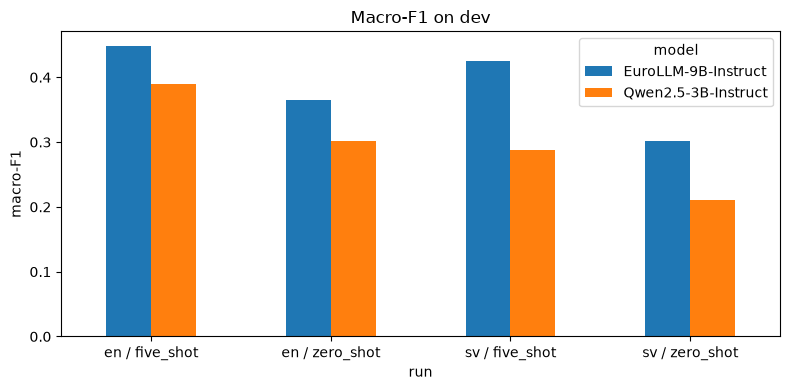

In [ ]:
ax = (
    summary.assign(run=summary["lang"] + " / " + summary["condition"]) 
    .pivot(index="run", columns="model", values="macro_f1")
    .plot.bar(figsize=(8, 4), rot=0)
)
ax.set_ylabel("macro-F1")
ax.set_title(f"Macro-F1 on {SPLIT}")
plt.tight_layout()
plt.show()

## 3. Five-shot gain and cross-lingual gap
Positive five-shot gain = demonstrations help. Positive EN−SV gap = the model is worse on Swedish.

In [ ]:
gain_gap = gain_and_gap(summary)
gain_gap

,five_shot_gain_en,five_shot_gain_sv,en_minus_sv_five_shot,en_minus_sv_zero_shot
model,,,,
EuroLLM-9B-Instruct,0.084,0.123,0.023,0.063
Qwen2.5-3B-Instruct,0.088,0.078,0.102,0.092


## 4. Output-format reliability
The spec asks for the malformed-output rate separately. `strict_json_rate` = whole output was exactly a JSON list; `wellformed_but_no_label_rate` = valid list but no permitted label (e.g. `[]`).

In [ ]:
format_df(summary)

malformed_rate  strict_json_rate  \
model               lang condition                                     
Qwen2.5-3B-Instruct en   zero_shot           0.002              0.99   
                         five_shot           0.000              1.00   
                    sv   zero_shot           0.000              1.00   
                         five_shot           0.000              1.00   
EuroLLM-9B-Instruct en   zero_shot           0.000              1.00   
                         five_shot           0.000              1.00   
                    sv   zero_shot           0.000              1.00   
                         five_shot           0.000              1.00   

                                    wellformed_but_no_label_rate  \
model               lang condition                                 
Qwen2.5-3B-Instruct en   zero_shot                         0.167   
                         five_shot                         0.038   
                    sv   zero_shot                         0.175   
                         five_shot                         0.080   
EuroLLM-9B-Instruct en   zero_shot                         0.006   
                         five_shot                         0.000   
                    sv   zero_shot                         0.000   
                         five_shot                         0.000   

                                    empty_prediction_rate  
model               lang condition                         
Qwen2.5-3B-Instruct en   zero_shot                  0.169  
                         five_shot                  0.038  
                    sv   zero_shot                  0.175  
                         five_shot                  0.080  
EuroLLM-9B-Instruct en   zero_shot                  0.006  
                         five_shot                  0.000  
                    sv   zero_shot                  0.000  
                         five_shot                  0.000

## 5. Per-emotion F1

In [ ]:
from llm_project.notebook_utils import per_label_f1

per_label_f1 = per_label_f1(summary, METRICS_DIR, LABELS)
display(per_label_f1)

Qwen2.5-3B-Instruct                                \
                              en                  sv             
                       zero_shot five_shot zero_shot five_shot   
anger                      0.321     0.483     0.170     0.375   
anticipation               0.388     0.467     0.280     0.387   
disgust                    0.176     0.387     0.028     0.330   
fear                       0.209     0.356     0.053     0.133   
joy                        0.317     0.449     0.240     0.434   
sadness                    0.422     0.451     0.389     0.279   
surprise                   0.180     0.086     0.262     0.043   
trust                      0.400     0.438     0.258     0.323   

             EuroLLM-9B-Instruct                               gold_support  
                              en                  sv                         
                       zero_shot five_shot zero_shot five_shot               
anger                      0.531     0.558     0.509     0.439          125  
anticipation               0.398     0.420     0.213     0.519          119  
disgust                    0.268     0.436     0.257     0.381           67  
fear                       0.421     0.374     0.360     0.384           67  
joy                        0.553     0.521     0.437     0.453           77  
sadness                    0.319     0.503     0.342     0.467           89  
surprise                   0.347     0.374     0.278     0.425           84  
trust                      0.080     0.403     0.022     0.337           87

/tmp/ipykernel_354559/1444035315.py:2: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  f1_only = per_label_f1.drop(columns="gold_support")


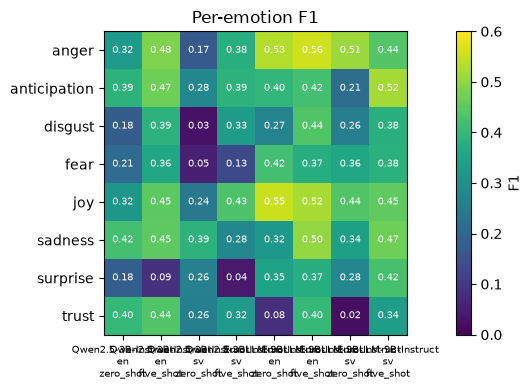

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
f1_only = per_label_f1.drop(columns="gold_support")
im = ax.imshow(f1_only.values, cmap="viridis", vmin=0, vmax=max(0.6, f1_only.values.max()))
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xticks(range(f1_only.shape[1]), ["\n".join(c) for c in f1_only.columns], fontsize=7)
for i in range(f1_only.shape[0]):
    for j in range(f1_only.shape[1]):
        ax.text(j, i, f"{f1_only.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, label="F1")
ax.set_title("Per-emotion F1")
plt.tight_layout()
plt.show()

## 6. Label cardinality, label distribution and empty predictions

In [ ]:
from llm_project.notebook_utils import load_preds

display(summary.set_index(["model", "lang", "condition"])[
    ["gold_label_cardinality", "pred_label_cardinality"]
])

gold_label_cardinality  \
model               lang condition                           
Qwen2.5-3B-Instruct en   zero_shot                   1.439   
                         five_shot                   1.439   
                    sv   zero_shot                   1.439   
                         five_shot                   1.439   
EuroLLM-9B-Instruct en   zero_shot                   1.439   
                         five_shot                   1.439   
                    sv   zero_shot                   1.439   
                         five_shot                   1.439   

                                    pred_label_cardinality  
model               lang condition                          
Qwen2.5-3B-Instruct en   zero_shot                   0.936  
                         five_shot                   1.410  
                    sv   zero_shot                   0.855  
                         five_shot                   1.201  
EuroLLM-9B-Instruct en   zero_shot                   1.181  
                         five_shot                   1.915  
                    sv   zero_shot                   1.193  
                         five_shot                   1.928

In [ ]:
from llm_project.notebook_utils import predicted_distribution

dist = predicted_distribution(summary, PRED_DIR, LABELS)
display(dist)

GOLD Qwen2.5-3B-Instruct                                \
                                   en                  sv             
                            zero_shot five_shot zero_shot five_shot   
anger         125                  43        86        28        83   
anticipation  119                 144       202        81       165   
disgust        67                  24       119         4       121   
fear           67                  19        34         8         8   
joy            77                  24        61        23        66   
sadness        89                  91        53        91        47   
surprise       84                  27         9        99         8   
trust          87                  93       137        91        99   

             EuroLLM-9B-Instruct                                
                              en                  sv            
                       zero_shot five_shot zero_shot five_shot  
anger                        146       101       146        71  
anticipation                  87       100        22       120  
disgust                       82       144        73       101  
fear                          47        88        83       110  
joy                          122       165       161       197  
sadness                       30        70        28        61  
surprise                      60        98        74        76  
trust                         13       186         6       222

In [ ]:
from llm_project.notebook_utils import empty_predictions_summary

for model, lang, condition, nempty, n, counts in empty_predictions_summary(summary, PRED_DIR):
    print(f"{model:28s} {lang} {condition:9s}: {nempty:4d}/{n} empty | gold of those: {counts}")

Qwen2.5-3B-Instruct          en zero_shot:   84/497 empty | gold of those: {'anger': 21, 'anticipation': 20, 'trust': 17, 'surprise': 14, 'joy': 14, 'sadness': 13, 'fear': 8, 'disgust': 7}
Qwen2.5-3B-Instruct          en five_shot:   19/497 empty | gold of those: {'anticipation': 6, 'anger': 5, 'surprise': 4, 'disgust': 2, 'sadness': 2, 'joy': 2, 'trust': 2, 'fear': 1}
Qwen2.5-3B-Instruct          sv zero_shot:   87/497 empty | gold of those: {'anger': 23, 'anticipation': 20, 'trust': 17, 'sadness': 17, 'joy': 14, 'surprise': 12, 'disgust': 9, 'fear': 7}
Qwen2.5-3B-Instruct          sv five_shot:   40/497 empty | gold of those: {'anticipation': 10, 'anger': 9, 'surprise': 9, 'joy': 7, 'trust': 6, 'sadness': 6, 'disgust': 4, 'fear': 1}
EuroLLM-9B-Instruct          en zero_shot:    3/497 empty | gold of those: {'trust': 1, 'fear': 1, 'anger': 1, 'disgust': 1, 'sadness': 1}
EuroLLM-9B-Instruct          en five_shot:    0/497 empty | gold of those: {}
EuroLLM-9B-Instruct          sv zero_s

## 7. Paired bootstrap: which differences are real?

Resamples the dev texts 1,000 times. For a comparison A vs B, the *same* resampled texts are
used for both (paired, matched by alignment ID), which removes the noise from which texts were sampled.
If the 95% interval of the difference excludes 0, the difference is unlikely to be noise.

In [ ]:
from llm_project.notebook_utils import load_preds, paired_bootstrap

models = summary["model"].unique()
langs = summary["lang"].unique()
comparisons = []
for mo in models:
    for la in langs:
        comparisons.append(("five vs zero", (mo, la, "zero_shot"), (mo, la, "five_shot")))
    for co in ["zero_shot", "five_shot"]:
        other = [l for l in langs if l != "en"][0]
        comparisons.append((f"{other} vs en", (mo, "en", co), (mo, other, co)))
if len(models) == 2:
    for la in langs:
        for co in ["zero_shot", "five_shot"]:
            comparisons.append(
                (f"{models[1]} vs {models[0]}", (models[0], la, co), (models[1], la, co))
            )

rows = []
for name, a, b in comparisons:
    try:
        da = load_preds(a[0], a[1], a[2], PRED_DIR).set_index(ID_KEY)
        db = load_preds(b[0], b[1], b[2], PRED_DIR).set_index(ID_KEY)
    except Exception:
        continue
    d, lo, hi, n = paired_bootstrap(da, db, labels=LABELS)
    rows.append({"comparison": name, "A": f"{a[0]} / {a[1]} / {a[2]}", "B": f"{b[0]} / {b[1]} / {b[2]}", "n_paired": n, "macro_f1_diff (B-A)": d, "ci_low": lo, "ci_high": hi, "significant": not (lo <= 0 <= hi)})
boot = pd.DataFrame(rows)
display(boot)

,comparison,A,B,n_paired,macro_f1_diff (B-A),ci_low,ci_high,significant
0,five vs zero,Qwen2.5-3B-Instruct / en / zero_shot,Qwen2.5-3B-Instruct / en / five_shot,497,0.088,0.052,0.122,True
1,five vs zero,Qwen2.5-3B-Instruct / sv / zero_shot,Qwen2.5-3B-Instruct / sv / five_shot,497,0.078,0.044,0.111,True
2,sv vs en,Qwen2.5-3B-Instruct / en / zero_shot,Qwen2.5-3B-Instruct / sv / zero_shot,497,-0.092,-0.128,-0.054,True
3,sv vs en,Qwen2.5-3B-Instruct / en / five_shot,Qwen2.5-3B-Instruct / sv / five_shot,497,-0.102,-0.134,-0.066,True
4,five vs zero,EuroLLM-9B-Instruct / en / zero_shot,EuroLLM-9B-Instruct / en / five_shot,497,0.084,0.051,0.117,True
5,five vs zero,EuroLLM-9B-Instruct / sv / zero_shot,EuroLLM-9B-Instruct / sv / five_shot,497,0.123,0.089,0.157,True
6,sv vs en,EuroLLM-9B-Instruct / en / zero_shot,EuroLLM-9B-Instruct / sv / zero_shot,497,-0.063,-0.102,-0.027,True
7,sv vs en,EuroLLM-9B-Instruct / en / five_shot,EuroLLM-9B-Instruct / sv / five_shot,497,-0.023,-0.055,0.006,False
8,EuroLLM-9B-Instruct vs Qwen2.5-3B-Instruct,Qwen2.5-3B-Instruct / en / zero_shot,EuroLLM-9B-Instruct / en / zero_shot,497,0.063,0.019,0.108,True
9,EuroLLM-9B-Instruct vs Qwen2.5-3B-Instruct,Qwen2.5-3B-Instruct / en / five_shot,EuroLLM-9B-Instruct / en / five_shot,497,0.059,0.026,0.096,True


## 8. Example errors
Read a sample of wrong predictions; use these for the qualitative error analysis.

In [ ]:
from llm_project.notebook_utils import show_errors

r0 = summary.iloc[0]
show_errors(r0["model"], [l for l in langs if l != "en"][0], "five_shot", PRED_DIR)

420/497 not exactly right


,text,gold,pred,raw_output
139,Flottstyrkan kommer hitåt.,[fear],[anticipation],"[""anticipation""]"
396,Jag såg en jätteskillnad mellan Dirk Harrimans prognos och budgeten för Mellanöstern.,[surprise],[],[]
25,Man begraver inte en berömd filmstjärna som en oidentifierad person.,"[disgust, sadness]",[disgust],"[""disgust""]"
106,Heja Tommy!,[anger],[joy],"[""joy""]"
147,- De svarar inte midskepps.,[fear],[],[]
196,"Kom in, min spion.",[anticipation],[disgust],"[""disgust""]"
10,Kanske är det därför jag inte kan fa barn.,[fear],"[sadness, trust]","[""sadness"", ""trust""]"
297,Det är så den här branschen drivs.,"[joy, trust]",[disgust],"[""disgust""]"
210,Vår sida vinner alltid.,"[joy, trust]",[joy],"[""joy""]"
348,Mitt liv har bara plats för sanning.,"[anticipation, trust]","[sadness, trust]","[""trust"", ""sadness""]"


## 9. Wording sensitivity (dev only)
Only runs if `scripts/run_prompting.py --split dev --sensitivity` has finished.

In [14]:
sens_path = METRICS_DIR / "summary_sensitivity.csv"
if sens_path.exists():
    sens = pd.read_csv(sens_path)
    table = sens.pivot_table(
        index=["model", "lang", "condition"], columns="variant", values="macro_f1"
    )
    table["range"] = table.max(axis=1) - table.min(axis=1)
    table["std"] = table.drop(columns="range").std(axis=1)
    display(table)
    display(
        sens.pivot_table(
            index=["model", "lang", "condition"], columns="variant", values="malformed_rate"
        )
    )
else:
    print("No sensitivity results yet: sbatch jobs/run_prompting.sh dev --sensitivity")

variant                             default  no_format_example  paraphrase  \
model               lang condition                                           
EuroLLM-9B-Instruct en   five_shot    0.449              0.448       0.459   
                         zero_shot    0.365              0.403       0.404   
                    sv   five_shot    0.425              0.423       0.425   
                         zero_shot    0.302              0.352       0.369   

variant                             terse  range    std  
model               lang condition                       
EuroLLM-9B-Instruct en   five_shot  0.434  0.024  0.010  
                         zero_shot  0.374  0.039  0.020  
                    sv   five_shot  0.417  0.009  0.004  
                         zero_shot  0.340  0.067  0.028

variant                             default  no_format_example  paraphrase  \
model               lang condition                                           
EuroLLM-9B-Instruct en   five_shot      0.0                0.0         0.0   
                         zero_shot      0.0                0.0         0.0   
                    sv   five_shot      0.0                0.0         0.0   
                         zero_shot      0.0                0.0         0.0   

variant                             terse  
model               lang condition         
EuroLLM-9B-Instruct en   five_shot    0.0  
                         zero_shot    0.0  
                    sv   five_shot    0.0  
                         zero_shot    0.0